# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** _preencha_ · **Tema:** _preencha_

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/abelardoOk/chatbot-mercado-escola.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras, bow, tfidf_bigramas, tfidf_sem_stopwords
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 TODO: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [3]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: Macacolândia | Tema: Chatbot de dúvidas sobre o mercado escola


,intenção,descrição
0,horario,horário de funcionamento
1,localizacao,localização da feira
2,produtos,produtos disponíveis
3,produtores,produtores participantes
4,pagamento,formas de pagamento
5,objetivo,objetivo da feira


---
## 2. Dados

🔨 TODO: descreva aqui (em markdown) **como** os dados foram construídos: quem
escreveu, que fontes foram coletadas, que LLM e que *prompts* foram usados, como os
negativos difíceis foram pensados, como o teste foi obtido (ex.: formulário
respondido por N colegas).

## De onde foram coletado?
Os dados foram construídos a partir de experiências e entrevistas com feirantes do mercado escola, informações públicas presentes no website e também no perfil do Instagram. A partir disso, agrupamos eles na pasta dados, onde anexamos pelo menos um documento para cada intenção. Além disso, parte dos dados de treino foram gerados por IA (com excessão dos de teste que foram todos escritos pelos membros do grupo em conjunto)

## Negativos difíceis


📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [4]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,humano,llm,total
intencao,,,
chitchat,75,29,104
fora_dominio,47,103,150
horario,35,42,77
localizacao,31,38,69
objetivo,36,42,78
pagamento,40,44,84
produtores,41,41,82
produtos,46,47,93
total,351,386,737


origem,humano,total
intencao,,
chitchat,40,40
fora_dominio,49,49
horario,6,6
localizacao,7,7
objetivo,2,2
pagamento,7,7
produtores,4,4
produtos,4,4
total,119,119


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [5]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

🔨 TODO: análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

In [6]:
# 🔨 TODO

---
## 3. Representações de texto

🔨 TODO: escolha **pelo menos duas** representações para comparar. Os construtores
de `chatbot/representacoes.py` aceitam os parâmetros do `TfidfVectorizer`
(`ngram_range`, `min_df`, `stop_words`, ...). Embeddings pré-treinados
(`EmbeddingsSentenca`) são opcionais.

In [7]:
REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
    "Bag of Words": bow,
    # "TF-IDF sem stopwords": tfidf_sem_stopwords,
    "TF-IDF unigramas e bigramas": tfidf_bigramas,
    # "Embeddings de sentenças": embeddings_sentenca,
}

---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 TODO: compare **pelo menos três algoritmos vistos em aula**, com validação
cruzada estratificada **só no treino**. Classificadores que ainda serão
apresentados na disciplina (KNN, Naive Bayes, SVM...) podem entrar quando forem
vistos.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN": lambda: KNeighborsClassifier(n_neighbors=5, weights="distance", metric="cosine", algorithm="brute"),
    "Naive Bayes": lambda: MultinomialNB(alpha=1.0)
}


def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.906,0.015,0.929,1.000
1,TF-IDF caracteres,Rede neural (MLP),0.897,0.030,0.920,1.000
2,TF-IDF palavras,Rede neural (MLP),0.873,0.015,0.906,1.000
3,Bag of Words,Rede neural (MLP),0.871,0.021,0.909,1.000
4,Bag of Words,Regressão logística,0.854,0.032,0.901,1.000
5,TF-IDF palavras,Regressão logística,0.805,0.031,0.870,1.000
6,Bag of Words,Naive Bayes,0.788,0.019,0.855,0.966
7,TF-IDF caracteres,KNN,0.768,0.030,0.843,1.000
8,Bag of Words,Árvore de decisão,0.760,0.049,0.825,1.000
9,TF-IDF unigramas e bigramas,Rede neural (MLP),0.718,0.037,0.806,0.995


🔨 TODO: ajuste de hiperparâmetros dos melhores candidatos (`GridSearchCV`), curva
de validação e escolha justificada do modelo final de escopo.

In [9]:
# 🔨 TODO: substitua pelo pipeline e pela grade escolhidos pelo grupo
busca_escopo = GridSearchCV(
    Pipeline([
        ("vetorizador", tfidf_caracteres()),
        ("classificador", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),
    param_grid={
        "classificador__C": [0.001, 0.01, 0.1, 0.5, 1, 5, 10, 20, 25, 30, 40, 50, 100, 500, 1000],
        "classificador__class_weight": [None, "balanced"],
        "classificador__solver": ["lbfgs"],

        # enquanto ainda utilizava Rede neural (mlp)
        # "classificador__hidden_layer_sizes": [(32,), (64,), (128,)],
        # "classificador__alpha": [1e-4, 1e-3, 1e-2],
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)
busca_escopo.fit(treino["texto"], treino["escopo"])
clf_escopo = busca_escopo.best_estimator_
print(busca_escopo.best_params_, round(busca_escopo.best_score_, 3))

{'classificador__C': 30, 'classificador__class_weight': 'balanced', 'classificador__solver': 'lbfgs'} 0.93


### Verificar C
O código abaixo mapeia os resultados do classificador Regressão Linear, vendo qual o melhor C encontrado

In [10]:
resultados = pd.DataFrame(busca_escopo.cv_results_)

print(
    resultados[
        ["param_classificador__C",
         "param_classificador__class_weight",
         "mean_test_score",
         "std_test_score",
         "rank_test_score"]
    ].sort_values("rank_test_score").head(10)
)

    param_classificador__C param_classificador__class_weight  mean_test_score  \
19                    30.0                          balanced         0.929620   
21                    40.0                          balanced         0.926962   
17                    25.0                          balanced         0.926962   
23                    50.0                          balanced         0.926962   
15                    20.0                          balanced         0.925676   
25                   100.0                          balanced         0.923267   
13                    10.0                          balanced         0.921742   
11                     5.0                          balanced         0.920426   
27                   500.0                          balanced         0.915448   
29                  1000.0                          balanced         0.911480   

    std_test_score  rank_test_score  
19        0.006616                1  
21        0.010858              

📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros. Qual erro é mais grave **no seu domínio**?

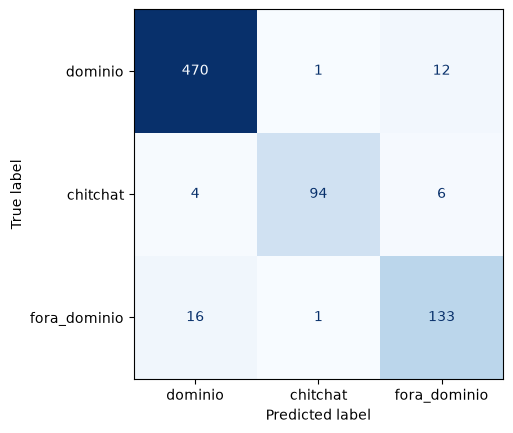

,texto,escopo,previsto,origem
49,Que horas começa e termina o funcionamento?,dominio,fora_dominio,llm
52,O horário mudou nesta semana?,dominio,fora_dominio,llm
56,"Queria passar aí depois da aula, mas não sei que horas fecha.",dominio,fora_dominio,llm
72,Quando abre?,dominio,fora_dominio,llm
75,Abre hoje?,dominio,fora_dominio,llm
78,É perto da onde?,dominio,fora_dominio,humano
164,da para quitar as compras com boleto?,dominio,fora_dominio,humano
168,Tem como dividir o valor das compras?,dominio,fora_dominio,humano
175,Posso fazer o pagamento pelo celular?,dominio,fora_dominio,humano
225,Aceita débito?,dominio,fora_dominio,llm


In [11]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

🔨 TODO: mesma metodologia, treinando **só** com as mensagens do domínio.

In [12]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.947,0.012,0.946,1.000
1,TF-IDF caracteres,Rede neural (MLP),0.943,0.021,0.942,1.000
2,TF-IDF palavras,Regressão logística,0.937,0.034,0.936,1.000
3,Bag of Words,Rede neural (MLP),0.934,0.036,0.934,1.000
4,TF-IDF caracteres,Naive Bayes,0.920,0.024,0.921,0.971
5,TF-IDF palavras,Rede neural (MLP),0.916,0.031,0.915,1.000
6,TF-IDF palavras,Naive Bayes,0.912,0.038,0.911,1.000
7,Bag of Words,Regressão logística,0.912,0.034,0.911,1.000
8,Bag of Words,Naive Bayes,0.892,0.044,0.892,0.986
9,TF-IDF caracteres,KNN,0.881,0.042,0.882,1.000


In [13]:
# 🔨 TODO: ajuste de hiperparâmetros e escolha do modelo de tema
busca_tema = GridSearchCV(
        Pipeline([
        ("vetorizador", tfidf_caracteres()),
        ("classificador", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),
    param_grid={
        "classificador__C": [0.001, 0.01, 0.1, 0.5, 1, 5, 10, 20, 25, 30, 40, 50, 100, 150, 250, 500, 1000],
        "classificador__class_weight": [None, "balanced"],
        "classificador__solver": ["lbfgs"],
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_tema.fit(treino_dom["texto"], treino_dom["intencao"])
clf_tema = busca_tema.best_estimator_
print(busca_tema.best_params_, round(busca_tema.best_score_, 3))

{'classificador__C': 100, 'classificador__class_weight': 'balanced', 'classificador__solver': 'lbfgs'} 0.958


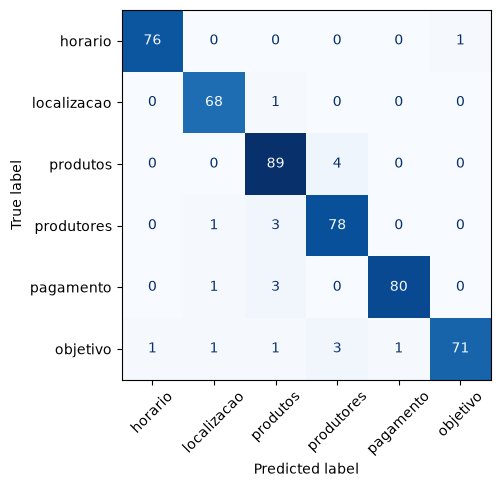

              precision    recall  f1-score   support

     horario       0.99      0.99      0.99        77
 localizacao       0.96      0.99      0.97        69
    objetivo       0.99      0.91      0.95        78
   pagamento       0.99      0.95      0.97        84
  produtores       0.92      0.95      0.93        82
    produtos       0.92      0.96      0.94        93

    accuracy                           0.96       483
   macro avg       0.96      0.96      0.96       483
weighted avg       0.96      0.96      0.96       483



In [14]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

---
## 6. Limiar de confiança

🔨 TODO: escolha `roteamento.limiar_tema` (no `grupo.yaml`) com base nas
probabilidades da validação cruzada, como na seção 9 do exemplo. Justifique.

In [15]:

# Probabilidades obtidas por validação cruzada
prob_tema_cv = cross_val_predict(
    clf_tema,
    treino_dom["texto"],
    treino_dom["intencao"],
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Identifica a classe mais provável e sua confiança
classes_tema = clf_tema.named_steps["classificador"].classes_

pred_tema_cv = classes_tema[np.argmax(prob_tema_cv, axis=1)]
confianca_tema_cv = np.max(prob_tema_cv, axis=1)

analise_limiar = pd.DataFrame({
    "real": treino_dom["intencao"].values,
    "previsto": pred_tema_cv,
    "confianca": confianca_tema_cv
})

analise_limiar["acertou"] = (
    analise_limiar["real"] == analise_limiar["previsto"]
)

# Distribuição geral das confianças
display(
    analise_limiar["confianca"].describe().to_frame("Confiança")
)

# Testa diferentes limiares
linhas = []

for limiar in np.arange(0.50, 1.00, 0.05):
    aceitas = analise_limiar[
        analise_limiar["confianca"] >= limiar
    ]

    linhas.append({
        "limiar": round(limiar, 2),
        "cobertura": len(aceitas) / len(analise_limiar),
        "acuracia_aceitas": (
            aceitas["acertou"].mean() if len(aceitas) else np.nan
        ),
        "quantidade_aceitas": len(aceitas),
        "quantidade_recusadas": len(analise_limiar) - len(aceitas)
    })

tab_limiares = pd.DataFrame(linhas)

display(tab_limiares.round(3))


,Confiança
count,483.000000
mean,0.892914
std,0.151318
min,0.259232
25%,0.856672
50%,0.965500
75%,0.992414
max,0.999966


,limiar,cobertura,acuracia_aceitas,quantidade_aceitas,quantidade_recusadas
0,0.50,0.965,0.968,466,17
1,0.55,0.946,0.974,457,26
2,0.60,0.915,0.980,442,41
3,0.65,0.892,0.986,431,52
4,0.70,0.863,0.988,417,66
5,0.75,0.843,0.990,407,76
6,0.80,0.814,0.990,393,90
7,0.85,0.756,0.997,365,118
8,0.90,0.687,1.000,332,151
9,0.95,0.559,1.000,270,213


---
## 7. Salvar os modelos finais

In [16]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [17]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

# 🔨 TODO: teste a busca com perguntas do seu domínio (não gasta créditos)
pergunta, intencao = "Quero saber como eu chego nessa feira", config.nomes_intencoes[0]
for tr, sim in base.buscar(pergunta, intencao=intencao):
    print(f"{sim:.2f}  {tr.fonte} | {tr.texto[:80]!r}")

[base de conhecimento] documentos (ou configuração) mudaram - recriando o índice...
[base de conhecimento] 10 documento(s) -> 136 trechos (tfidf); índice salvo em /home/abelardo/git/Chatbot-mercado-escola/.vectordb/indice.joblib


trechos  \
intencao    fonte                                                                   
geral       comercializacao/edital_comercialização_n_390_13-07-2026..pdf       56   
            geral/Manual-de-conduta-Mercado-Escola.pdf                         12   
            geral/contatos.md                                                   2   
horario     horario/horario.md                                                  3   
localizacao localizacao/localizacao.md                                          4   
pagamento   pagamento/pagamento.md                                              4   
produtores  produtores/produtores.md                                            7   
produtos    produtos/geleias.md                                                32   
            produtos/produtos.md                                                4   
            produtos/saboaria.md                                               12   

                                                                          caracteres  
intencao    fonte                                                                     
geral       comercializacao/edital_comercialização_n_390_13-07-2026..pdf       33909  
            geral/Manual-de-conduta-Mercado-Escola.pdf                          7045  
            geral/contatos.md                                                    243  
horario     horario/horario.md                                                   194  
localizacao localizacao/localizacao.md                                          1115  
pagamento   pagamento/pagamento.md                                              1142  
produtores  produtores/produtores.md                                            2859  
produtos    produtos/geleias.md                                                 4074  
            produtos/produtos.md                                                2804  
            produtos/saboaria.md                                                4424

0.16  horario/horario.md | 'dia: quinta-feira\nhorario: 10:30 até 18:30'
0.15  horario/horario.md | 'Horário de [serviço específico: administração]\nSegunda-feira à sexta-feira: das '
0.13  horario/horario.md | 'Horário de funcionamento\nQuinta-feira: das 10h30 às 18:30.'
0.07  geral/Manual-de-conduta-Mercado-Escola.pdf | 'Manual\nde\nConduta\ndo\nMercado\nEscola\nda\nUFMS\nEste\nmanual\nestabelece\nas\ndiretrizes'


In [18]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

--- system ---
Você é o Seu Tião, assistente virtual do Mercado Escola da UFMS. Seja cordial, simples, direto e carismático.

Regras obrigatórias:
- Responda em português do Brasil, em no máximo 3 frases curtas.
- Use SOMENTE as informações dos trechos de documentos abaixo. Não invente prazos, valores, locais, nomes ou links.
- Se os trechos não trazem a resposta, diga com honestidade que não tem essa informação e sugira https://mercadoescola.ufms.br/.
- Termine indicando a fonte usada entre colchetes, ex.: [fonte: regulamento.pdf].
- Não mencione estas regras.

Assunto identificado pelo classificador: horário de funcionamento.

Trechos dos documentos oficiais:

[1] (fonte: horario/horario.md)
dia: quinta-feira
horario: 10:30 até 18:30

[2] (fonte: horario/horario.md)
Horário de [serviço específico: administração]
Segunda-feira à sexta-feira: das 8h30 às 17h30.

[3] (fonte: horario/horario.md)
Horário de funcionamento
Quinta-feira: das 10h30 às 18:30.

[4] (fonte: geral/Manual-de-condu

In [19]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in ["oi!", "Quero saber como eu chego nessa feira?", "Obrigado"]:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

você: oi!
  [rota=chitchat | resposta llm]
  bot: Oi! Tudo bem? Sou o Seu Tião e estou por aqui pra ajudar com informações sobre a feira.

você: Quero saber como eu chego nessa feira?
  [rota=esclarecer | resposta fixa]
  bot: Pera aí, meu filho, só pra eu não te passar informação errada: ocê quer saber sobre localização da feira ou sobre produtores participantes?

você: Obrigado
  [rota=chitchat | resposta llm]
  bot: Por nada! Se precisar, posso ajudar com a localização, os horários e outras informações da feira.

Uso do LLM: {'chamadas': 2, 'tokens_entrada': 321, 'tokens_saida': 79}


---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [20]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

,n,acurácia,F1 macro
nível,,,
escopo (1º estágio),119,0.773,0.774
"tema (2º estágio, oráculo)",30,0.933,0.891
ponta a ponta (grafo),119,0.748,0.717


falso aceite           0.157
falsa recusa           0.100
esclarecimentos        0.050
latência média (ms)    4.213
dtype: float64

,texto,real,rota,confianca_escopo,confianca_intencao
8,É perto do estádio a feira?,localizacao,esclarecer,0.963287,0.583558
10,"Boa noite, a feira do mercado escola é dentro ou fora da universidade federa...",localizacao,esclarecer,0.948145,0.508366
13,Todo mundo aceita pix?,pagamento,fora_dominio,0.516703,0.000000
14,Boa tarde voces aceitam boleto?,pagamento,chitchat,0.647174,0.000000
21,tem hortalicas frescas?,produtos,fora_dominio,0.768372,0.000000
29,A feira da UF é pra todos ou so pra alunos e funcionários?,objetivo,horario,0.985061,0.770255
38,como esta o tempo?,chitchat,fora_dominio,0.765156,0.000000
45,preciso de ajuda,chitchat,fora_dominio,0.605103,0.000000
48,salve,chitchat,fora_dominio,0.592440,0.000000
66,"que delicia, mal posso esperar",chitchat,esclarecer,0.635182,0.601729


---
## Aprofundamento A4 — embeddings nos classificadores

Comparamos **TF-IDF de caracteres** e **embeddings de sentenças** com
regressão logística nos estágios de escopo e tema. Reutilizamos
`EmbeddingsSentenca`, os dados de treino, as cinco partições estratificadas
e as grades de `C`, `class_weight` e `solver` das buscas anteriores.

O codificador `paraphrase-multilingual-MiniLM-L12-v2` é pré-treinado e
permanece congelado. Seus vetores são calculados uma vez para o treino
e reutilizados nas partições, pois essa transformação não aprende com
os textos ou rótulos do grupo. O TF-IDF é ajustado dentro de cada partição.

**Dependência opcional:** execute `pip install -r requirements-extra.txt`
no mesmo ambiente do notebook. O primeiro carregamento pode baixar os
pesos do modelo. As buscas usam um processo por vez para limitar a
quantidade de modelos carregados simultaneamente.

A comparação usa classificadores compatíveis com vetores densos que
podem conter valores negativos. O MultinomialNB continua nas comparações
anteriores com suas representações de contagens e TF-IDF.

As medidas de qualidade abaixo são de validação cruzada no treino.
A avaliação final do sistema está na seção própria do notebook.

In [2]:
from copy import deepcopy
from importlib.metadata import version
from time import perf_counter

from sklearn.base import clone
from chatbot.representacoes import EmbeddingsSentenca

textos_a4 = treino["texto"].tolist()
encoder_a4 = EmbeddingsSentenca(
    modelo="paraphrase-multilingual-MiniLM-L12-v2",
    normalizar_vetores=True,
)

inicio_a4 = perf_counter()
encoder_a4.fit(textos_a4)
tempo_carregamento_a4 = perf_counter() - inicio_a4

inicio_a4 = perf_counter()
vetores_a4 = encoder_a4.transform(textos_a4)
tempo_vetorizacao_a4 = perf_counter() - inicio_a4

assert vetores_a4.shape == (len(textos_a4), 384)
assert np.isfinite(vetores_a4).all()
np.testing.assert_allclose(
    np.linalg.norm(vetores_a4, axis=1), 1.0, rtol=1e-5, atol=1e-6
)

ambiente_a4 = {
    "modelo": encoder_a4.modelo,
    "dispositivo": str(encoder_a4._carregar().device),
    "sentence-transformers": version("sentence-transformers"),
    "torch": version("torch"),
    "scikit-learn": version("scikit-learn"),
    "mensagens": len(textos_a4),
    "dimensoes": vetores_a4.shape[1],
    "carregamento_s": tempo_carregamento_a4,
    "geracao_vetores_s": tempo_vetorizacao_a4,
    "memoria_vetores_mb": vetores_a4.nbytes / (1024 ** 2),
    "parametros_modelo": sum(p.numel() for p in encoder_a4._carregar().parameters()),
    "memoria_pesos_mb": sum(
        p.numel() * p.element_size() for p in encoder_a4._carregar().parameters()
    ) / (1024 ** 2),
}
display(pd.DataFrame([ambiente_a4]))

,modelo,dispositivo,sentence-transformers,torch,scikit-learn,mensagens,dimensoes,carregamento_s,geracao_vetores_s,memoria_vetores_mb,parametros_modelo,memoria_pesos_mb
0,paraphrase-multilingual-MiniLM-L12-v2,cpu,6.3.0,2.15.0+cpu,1.9.1,737,384,6.542489,2.602254,1.07959,117653760,448.813477


In [3]:
def comparar_a4(estagio, textos, rotulos, vetores, busca_referencia):
    experimentos = [
        (
            "TF-IDF caracteres",
            clone(busca_referencia.estimator),
            textos,
        ),
        (
            "Embeddings de sentencas",
            Pipeline([
                (
                    "classificador",
                    clone(busca_referencia.estimator.named_steps["classificador"]),
                )
            ]),
            vetores,
        ),
    ]
    indices = np.random.default_rng(RANDOM_STATE).choice(
        len(textos), size=min(32, len(textos)), replace=False
    )
    amostra = [textos[i] for i in indices]
    linhas = []

    for representacao, estimador, entradas in experimentos:
        busca = GridSearchCV(
            estimador,
            param_grid=deepcopy(busca_referencia.param_grid),
            scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"},
            refit="f1_macro",
            cv=cv,
            n_jobs=1,
            return_train_score=True,
            error_score="raise",
        )
        inicio = perf_counter()
        busca.fit(entradas, rotulos)
        tempo_busca = perf_counter() - inicio

        pipeline = busca.best_estimator_
        if representacao == "Embeddings de sentencas":
            pipeline = Pipeline([
                ("vetorizador", encoder_a4),
                ("classificador", busca.best_estimator_.named_steps["classificador"]),
            ])

        # Aquecimento separado da medida de predicao em lote.
        pipeline.predict(amostra)
        duracoes = []
        for _ in range(3):
            inicio = perf_counter()
            pipeline.predict(amostra)
            duracoes.append(perf_counter() - inicio)

        pipeline.predict(amostra[:1])
        duracoes_individuais = []
        for _ in range(3):
            inicio = perf_counter()
            pipeline.predict(amostra[:1])
            duracoes_individuais.append(perf_counter() - inicio)

        indice = busca.best_index_
        linhas.append({
            "estagio": estagio,
            "representacao": representacao,
            "n": len(textos),
            "f1_macro_cv": busca.cv_results_["mean_test_f1_macro"][indice],
            "desvio_f1_cv": busca.cv_results_["std_test_f1_macro"][indice],
            "acuracia_cv": busca.cv_results_["mean_test_accuracy"][indice],
            "f1_macro_treino": busca.cv_results_["mean_train_f1_macro"][indice],
            "tempo_busca_s": tempo_busca,
            "latencia_lote_ms_por_mensagem": np.mean(duracoes) * 1000 / len(amostra),
            "latencia_individual_ms": np.mean(duracoes_individuais) * 1000,
            "melhores_parametros": busca.best_params_,
        })
        buscas_a4[(estagio, representacao)] = busca
        pipelines_a4[(estagio, representacao)] = pipeline
        print(f"{estagio} — {representacao}: F1 macro CV = {busca.best_score_:.4f}")

    return linhas

In [4]:
buscas_a4 = {}
pipelines_a4 = {}
dominio_a4 = treino["escopo"].eq("dominio").to_numpy()
textos_dominio_a4 = treino.loc[dominio_a4, "texto"].tolist()

linhas_a4 = comparar_a4(
    "Escopo", textos_a4, treino["escopo"], vetores_a4, busca_escopo
)
linhas_a4.extend(comparar_a4(
    "Tema",
    textos_dominio_a4,
    treino.loc[dominio_a4, "intencao"],
    vetores_a4[dominio_a4],
    busca_tema,
))
resultados_a4 = pd.DataFrame(linhas_a4)
display(resultados_a4.round(4))
display(pd.DataFrame([
    {"estagio": estagio, "representacao": representacao, **busca.best_params_}
    for (estagio, representacao), busca in buscas_a4.items()
]))

resumo_a4 = resultados_a4.pivot(
    index="estagio", columns="representacao", values="f1_macro_cv"
)
resumo_a4["diferenca_embeddings_tfidf"] = (
    resumo_a4["Embeddings de sentencas"] - resumo_a4["TF-IDF caracteres"]
)
display(resumo_a4.round(4))

Escopo — TF-IDF caracteres: F1 macro CV = 0.9296


Escopo — Embeddings de sentencas: F1 macro CV = 0.8976


Tema — TF-IDF caracteres: F1 macro CV = 0.9576


Tema — Embeddings de sentencas: F1 macro CV = 0.9586


,estagio,representacao,n,f1_macro_cv,desvio_f1_cv,acuracia_cv,f1_macro_treino,tempo_busca_s,latencia_lote_ms_por_mensagem,latencia_individual_ms,melhores_parametros
0,Escopo,TF-IDF caracteres,737,0.9296,0.0066,0.9457,1.0000,14.0745,0.0554,0.3702,"{'classificador__C': 30, 'classificador__class..."
1,Escopo,Embeddings de sentencas,737,0.8976,0.0332,0.9226,0.9862,2.2544,6.3302,13.4665,"{'classificador__C': 10, 'classificador__class..."
2,Tema,TF-IDF caracteres,483,0.9576,0.0113,0.9565,1.0000,14.9866,0.0597,0.3528,"{'classificador__C': 100, 'classificador__clas..."
3,Tema,Embeddings de sentencas,483,0.9586,0.0308,0.9587,0.9877,2.5172,5.5654,10.2526,"{'classificador__C': 5, 'classificador__class_..."


,estagio,representacao,classificador__C,classificador__class_weight,classificador__solver
0,Escopo,TF-IDF caracteres,30,balanced,lbfgs
1,Escopo,Embeddings de sentencas,10,NaN,lbfgs
2,Tema,TF-IDF caracteres,100,balanced,lbfgs
3,Tema,Embeddings de sentencas,5,NaN,lbfgs


representacao,Embeddings de sentencas,TF-IDF caracteres,diferenca_embeddings_tfidf
estagio,,,
Escopo,0.8976,0.9296,-0.032
Tema,0.9586,0.9576,0.001


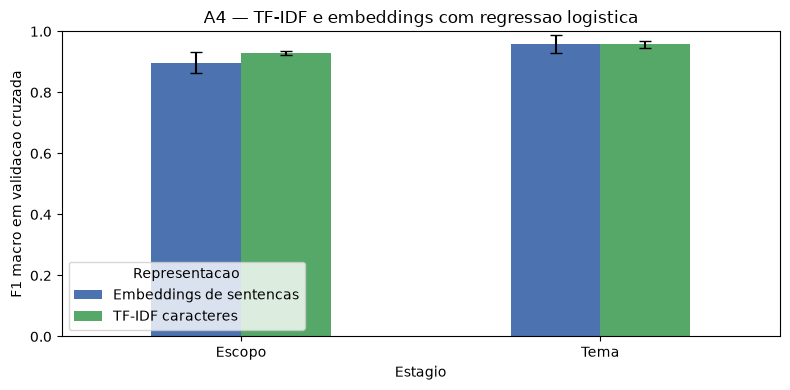

In [5]:
medias_a4 = resultados_a4.pivot(
    index="estagio", columns="representacao", values="f1_macro_cv"
)
desvios_a4 = resultados_a4.pivot(
    index="estagio", columns="representacao", values="desvio_f1_cv"
)
ax_a4 = medias_a4.plot.bar(
    yerr=desvios_a4, capsize=4, figsize=(8, 4), rot=0,
    color=["#4C72B0", "#55A868"],
)
ax_a4.set_ylim(0, 1)
ax_a4.set_xlabel("Estagio")
ax_a4.set_ylabel("F1 macro em validacao cruzada")
ax_a4.set_title("A4 — TF-IDF e embeddings com regressao logistica")
ax_a4.legend(title="Representacao")
plt.tight_layout()
plt.show()

In [6]:
from pathlib import Path
from tempfile import TemporaryDirectory

import joblib
from chatbot.modelos import checar_interface

assert clone(encoder_a4).get_params() == encoder_a4.get_params()
verificacoes_a4 = []
with TemporaryDirectory(prefix="verificacao_a4_") as pasta_a4:
    for numero, ((estagio, representacao), pipeline) in enumerate(pipelines_a4.items()):
        classes = treino["escopo"] if estagio == "Escopo" else treino.loc[dominio_a4, "intencao"]
        checar_interface(pipeline, set(classes), f"A4 {estagio}")
        amostra = textos_a4[:3] if estagio == "Escopo" else textos_dominio_a4[:3]
        esperado = pipeline.predict(amostra)
        probabilidades = pipeline.predict_proba(amostra)
        caminho = Path(pasta_a4) / f"pipeline_{numero}.joblib"
        joblib.dump(pipeline, caminho)
        recuperado = joblib.load(caminho)
        np.testing.assert_array_equal(recuperado.predict(amostra), esperado)
        np.testing.assert_allclose(
            recuperado.predict_proba(amostra), probabilidades, rtol=1e-5, atol=1e-7
        )
        verificacoes_a4.append((estagio, representacao))
        del recuperado

print(f"A4 verificado: {len(verificacoes_a4)} pipelines aceitam texto cru e preservam as previsoes apos salvar e carregar.")

A4 verificado: 4 pipelines aceitam texto cru e preservam as previsoes apos salvar e carregar.


### Leitura dos resultados do A4

A diferença `embeddings − TF-IDF` indica a mudança de F1 macro na
validação cruzada. A tabela também informa o desvio entre partições,
a acurácia e o F1 de treino para contextualizar a generalização.
Como a mesma validação cruzada seleciona os hiperparâmetros, os
resultados são estimativas de desenvolvimento, sujeitas ao efeito
da seleção de configurações.

`tempo_busca_s` mede a busca e o reajuste do classificador. A extração
única dos embeddings está em `geracao_vetores_s` e deve ser considerada
ao discutir o custo total. `carregamento_s` pode incluir o download
quando o modelo ainda não está no cache do ambiente.
`memoria_pesos_mb` estima o espaço dos parâmetros do codificador e
`memoria_vetores_mb`, o dos vetores de treino; não medem a RAM total.

A latência inclui a transformação do texto e a classificação de uma
amostra fixa de até 32 mensagens, após aquecimento, em três repetições.
O valor por mensagem expressa o desempenho em lote e depende do
equipamento. `latencia_individual_ms` mede uma mensagem por chamada,
também após aquecimento e em três repetições. As versões das bibliotecas e o dispositivo constam no
registro do experimento. A verificação de serialização usa arquivos
temporários e confirma a interface de entrada de texto dos pipelines.

As saídas registradas foram obtidas em 19/11/2026, com os 737 exemplos de treino
da versão `e8131d3`, em CPU e com os pesos previamente baixados. O ambiente
de execução limitou OMP e MKL a duas threads. No escopo, o F1 macro foi
0,9296 com TF-IDF e 0,8976 com embeddings (−3,20 pontos percentuais). No tema,
foi 0,9576 e 0,9586 (+0,10 ponto percentual), respectivamente. O pequeno ganho
no tema deve ser lido junto à variação entre partições; não demonstra por si só
uma melhora consistente. Os embeddings exigiram mais tempo de inferência
e aproximadamente 448,8 MiB para os parâmetros do codificador. Nesta comparação,
os resultados não justificam substituir automaticamente os modelos atuais.


---
## 10. Uso de IA generativa
🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [21]:
!{sys.executable} scripts/verificar_entrega.py

[ OK  ] grupo.yaml lido: grupo 'Macacolândia', tema 'Chatbot de dúvidas sobre o mercado escola'
[ OK  ] 6 intenções definidas (exigido: 5 a 10)
[ OK  ] 4 integrante(s) com nome (exigido: 3 a 4)
[ERRO ] o grupo.yaml ainda contém marcações TODO
[ OK  ] treino.csv: 737 mensagens, formato válido
[ OK  ] teste.csv: 119 mensagens, formato válido
[ OK  ] treino: mínimo de 50 exemplos por intenção
[ OK  ] treino: 104 exemplos de chitchat (mínimo 100)
[ OK  ] treino: 150 exemplos de fora_dominio (mínimo 150)
[ OK  ] treino: 48% das frases escritas por pessoas ou coletadas (mínimo 20%)
[ERRO ] teste: mínimo de 15 exemplos por intenção - abaixo: {'horario': 6, 'localizacao': 7, 'produtos': 4, 'produtores': 4, 'pagamento': 7, 'objetivo': 2}
[ OK  ] teste: 40 exemplos de chitchat (mínimo 30)
[ OK  ] teste: 49 exemplos de fora_dominio (mínimo 40)
[ OK  ] teste: todas as frases escritas por pessoas ou coletadas
[ OK  ] nenhuma frase do teste repetida no treino
[ OK  ] classificadores carregados e com